# Анализ оптовых продаж аудиотехники / Wholesale Audio Equipment Sales Analysis

## Бизнес-контекст / Business Context

«Карпов Саунд» — оптовая компания по продаже аудиотехники. В её ассортименте профессиональные аудиосистемы, домашние кинотеатры, портативные аудиоустройства и аксессуары от ведущих мировых брендов. Компания работает с крупными розничными сетями и специализированными магазинами аудиотехники по всей России.

Клиенты оставляют заявки на покупку через CRM-систему, менеджеры связываются с ними для обсуждения деталей, после чего заказы либо подтверждаются, либо отменяются. Из-за планового обслуживания хранилище данных компании было временно недоступно, поэтому все данные предоставили в виде резервной выгрузки, разложенной по нескольким папкам на сервере компании

<details>
<summary>&#9658; Click here to see the English version of the description</summary>
      
Karpov Sound is a wholesale audio equipment company. Its product range includes professional audio systems, home theaters, portable audio devices, and accessories from leading global brands. The company works with major retail chains and specialized audio stores across Russia.

Clients submit purchase requests through the CRM system, managers contact them to discuss details, and orders are then either confirmed or canceled. Due to planned maintenance, the company's data warehouse was temporarily unavailable, so all data was provided as a backup export scattered across multiple folders on the company server.
    
</details>

## Цель / Objective

Собрать данные из разрозненных источников, проанализировать их и сделать выводы, которые помогут руководству компании принимать обоснованные тактические решения

<details>
<summary>&#9658; Click here to see the English version of the description</summary>
      
Collect data from disparate sources, analyze it, and draw conclusions that will help the company's management make sound tactical decisions
    
</details>

## Данные / Data Sources

- **orders** — детали заказов (`order_id`, `product_id`, `quantity`), хранятся в папках по дате и менеджеру по продажам.
- **order_status** — статусы заказов и информация о клиенте (`order_id`, `client_id`, `status`), хранятся рядом с заказами.
- **products** — детали товаров (`id`, `name`, `price in USD`), хранятся в папках по категории товара.
- **usd_rate.txt** — курс доллара США на каждый день анализируемого периода.

    У каждого заказа есть статус `confirmed` или `canceled`. Заказ может содержать несколько товаров. Если отменённый заказ был создан заново тем же клиентом с теми же товарами и менеджером, в базе сохраняются обе записи с разными order_id и статусами

<details>
<summary>&#9658; Click here to see the English version of the description</summary>
      
- **orders** — order details (`order_id`, `product_id`, `quantity`), stored in folders by date and sales manager.
- **order_status** — order statuses and client info (`order_id`, `client_id`, `status`), stored alongside orders.
- **products** — product details (`id`, `name`, `price` in USD), stored in folders by product category.
- **usd_rate.txt** — USD exchange rate for each day of the analyzed period.
      
    Each order has either a `confirmed` or `canceled` status. An order may contain multiple products. If a canceled order was re-created by the same client with the same products and manager, the database keeps both records with different order IDs and statuses
</details>

## Шаг 0. Импортируем библиотеки / Step 0. Import libraries

In [1]:
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

## Шаг 1. Сбор и предобработка данных / Step 1. Data collection and preprocessing

Данные разложены по папкам: 

`orders` — по датам и менеджерам, 

`products` — по категориям. 

Собираю все CSV-файлы в три датафрейма, добавляю колонки `manager`, `date` и `category` (извлекаю из пути к файлу), объединяю и сортирую

<details>
<summary>&#9658; Click here to see the English version of the description</summary>
  <p>
The data is organized in folders: 
      
`orders` — by dates and managers, 
      
`products` — by categories. 
      
I collect all CSV files into three dataframes, add the columns `manager`, `date`, and `category` (taken from the file path), then combine and sort them
    
      
</p>
</details>

In [2]:
way = 'data/'

target_files = ['orders.csv', 'order_status.csv', 'products.csv']

data_files = []   

for path, dirs, files in os.walk(way):
    for file in files:
        if file.endswith('.csv'):
            data_file = os.path.join(path, file)
            data_files.append(data_file)            
            
df_orders = pd.DataFrame()
df_order_status = pd.DataFrame()
df_products = pd.DataFrame()

orders_df_list = []
order_status_df_list = []
products_df_list = []

for file_path in data_files:
    file_name = os.path.basename(file_path)

    if file_name == target_files[0]: #orders
        df = pd.read_csv(file_path)
        df['manager'] = file_path.split('/')[-2]
        df['date'] = file_path.split('/')[-3]
        orders_df_list.append(df)

    elif file_name == target_files[1]: #order_status
        df = pd.read_csv(file_path)
        order_status_df_list.append(df)

    elif file_name == target_files[2]: #products
        df = pd.read_csv(file_path)
        df['category'] = file_path.split('/')[-2]
        products_df_list.append(df)
        
df_orders = pd.concat(orders_df_list, ignore_index=True)
df_orders = df_orders.sort_values(by=['order_id', 'product_id'])  

df_order_status = pd.concat(order_status_df_list, ignore_index=True)
df_order_status = df_order_status.sort_values(by='order_id') 

df_products = pd.concat(products_df_list, ignore_index=True)
df_products = df_products.sort_values(by='id') 

## Шаг 2. Динамика заказов и аномальные дни / Step 2. Order dynamics and anomalous days

Считаю число заказов по дням и строю линейный график, чтобы увидеть сезонность и дни, выбивающиеся из общей картины.

<details>
<summary>&#9658; Click here to see the English version of the description</summary>
  <p>
I count the number of orders by day and build a line chart to see seasonality and days that stand out from the general pattern
      
</p>
</details>

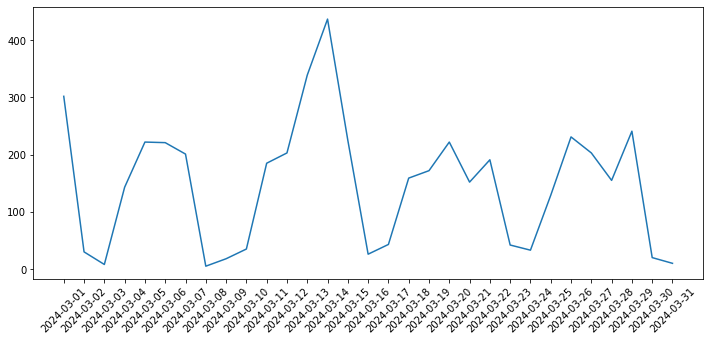

In [3]:
daily_orders = df_orders.groupby('date', as_index=False).agg({'order_id':'count'})

plt.figure(figsize=(12, 5))
plt.plot(daily_orders['date'], daily_orders['order_id'])
plt.xticks(rotation=45)

plt.show()

**Вывод:** в данных видна недельная сезонность — по выходным заказов создано заметно меньше. Один день резко выделяется по числу созданных заказов

<details>
<summary>&#9658; Click here to see the English version of the description</summary>
  <p>
      
**Conclusion:** the data shows weekly seasonality — noticeably fewer orders are created on weekends. One day stands out sharply in terms of the number of orders created
      
</p>
</details>

## Шаг 3. Статусы заказов и день без подтверждений / Step 3. Order statuses and the day without confirmations

Объединяю заказы со статусами в таблицу `orders_status`, считаю долю отменённых заказов и строю сводную таблицу «дата × статус», чтобы найти день, когда не было ни одного подтверждённого заказа

<details>
<summary>&#9658; Click here to see the English version of the description</summary>
  <p>
      
I join orders with statuses into the `orders_status` table, calculate the share of canceled orders, and build a pivot table "date × status" to find the day when there were no confirmed orders at all.
     
</p>
</details>

In [4]:
orders_status = pd.merge(df_orders, df_order_status, on='order_id', how='left')

all_orders = orders_status.order_id.count()
confirmed_orders = (orders_status.query("status == 'confirmed'").order_id.count()) * 100 / all_orders
canceled_orders = (orders_status.query("status == 'canceled'").order_id.count()) * 100 / all_orders

print(f"confirmed orders {confirmed_orders.round(2)}")
print(f"canceled orders {canceled_orders.round(2)}")

confirmed orders 88.7
canceled orders 11.3


In [5]:
order_status_grouped = orders_status \
                        .groupby(['date', 'status'], as_index=False)\
                        .agg({'order_id': 'count'})\
                        .rename(columns={'order_id': 'orders'})

# order_status_grouped.head()

In [6]:
order_status_pivot = order_status_grouped.pivot_table(
                        index='date',
                        columns='status',
                        values='orders',
                        fill_value=0,
                        )

In [7]:
order_status_pivot.query("confirmed == 0")

status,canceled,confirmed
date,,
2024-03-09,18,0


**Вывод:** доля отменённых заказов — около 11.3%. Найден день (2024-03-09), в который не было ни одного подтверждённого заказа — только отмены

<details>
<summary>&#9658; Click here to see the English version of the description</summary>
  <p>
      
**Conclusion:** the share of canceled orders is about 11.3%. A day was found (2024-03-09) with no confirmed orders at all — only cancellations
     
</p>
</details>

## Шаг 4. Анализ всплеска продаж / 

Строю график заказов по дням в разбивке по статусу и проверяю гипотезу: не является ли всплеск заказов на следующий день повторным оформлением отменённых заказов. 

Сравниваю отменённые заказы 13 марта с подтверждёнными 14 марта по менеджеру, клиенту, числу уникальных товаров и общему количеству штук

<details>
<summary>&#9658; Click here to see the English version of the description</summary>
  <p>
      
I build a chart of orders by day broken down by status and test the hypothesis: whether the spike in orders the next day is a re-creation of canceled orders. 
      
I compare canceled orders on March 13 with confirmed orders on March 14 by manager, client, number of unique products, and total quantity of items
     
</p>
</details>

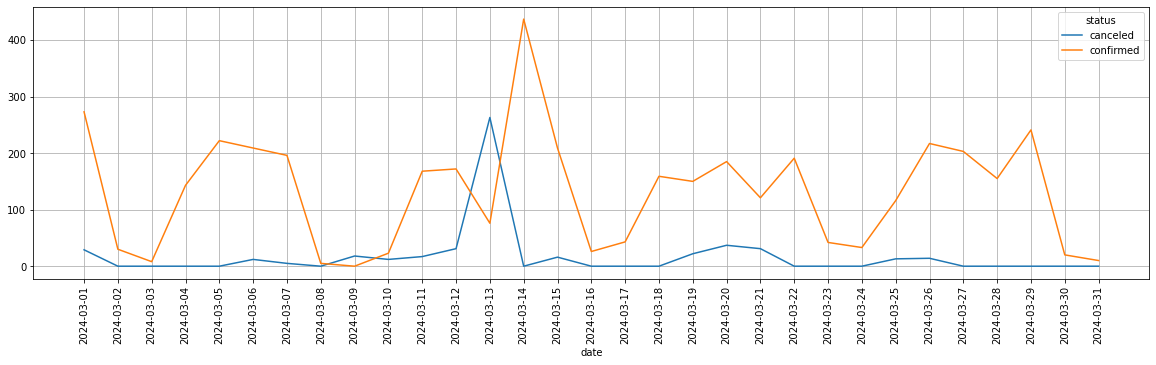

In [8]:
order_status_pivot.plot(kind='line', figsize=(20, 5))
plt.xticks(ticks=range(len(order_status_pivot)), labels=order_status_pivot.index, rotation=90)
plt.grid(True)

In [9]:
orders_status\
            .query("date == '2024-03-14' or date == '2024-03-13'")\
            .groupby(['manager', 'date', 'client_id'])\
            .agg({'order_id': 'count'})\
            .rename(columns={'order_id':'order_counts'})

order_counts
manager               date       client_id              
Алексей Саксофонов   2024-03-13 43                   11
                                 51                   17
                                 66                   18
                      2024-03-14 17                   11
                                 24                    8
                                 25                    9
                                 43                   11
                                 51                   17
                                 66                   18
Анастасия Дудкина     2024-03-14 39                    9
                                 94                   12
Виктор Тромбонов      2024-03-13 26                   10
                                 60                   13
                                 93                   15
                                 94                   15
                                 95                   14
                      2024-03-14 18                    5
                                 43                    9
                                 60                   13
                                 93                   15
                                 94                   15
                                 95                   22
Владимир Ударников    2024-03-13 38                   10
                      2024-03-14 38                   10
Екатерина Тарелкина   2024-03-13 31                   12
                                 56                   13
                                 83                   19
                      2024-03-14 56                   13
                                 68                   18
                                 83                   19
Ксения Балалайкина   2024-03-13 7                     4
                                 73                   14
                                 75                   12
                      2024-03-14 7                     4
                                 67                   17
                                 73                   14
                                 75                   12
Максим Барабанов      2024-03-13 23                   20
                      2024-03-14 53                    8
                                 87                   20
Маргарита Камертонова 2024-03-13 26                   16
                                 56                   16
                                 59                   12
                                 68                   32
                                 76                   18
                                 77                    8
                                 99                   20
                      2024-03-14 18                    9
                                 26                   16
                                 30                   20
                                 56                   16
                                 68                   14
                                 76                   18
Надежда Гармошкина    2024-03-14 11                   15
                                 53                    8
Сергей Контрабасов   2024-03-14 93                   12

**Вывод:** график и таблица подтверждают гипотезу о сбое CRM: значительная часть заказов, отменённых 13 марта, была оформлена заново 14 марта теми же клиентами у тех же менеджеров. Это объясняет всплеск — не рост спроса, а повторное оформление после сбоя.

<details>
<summary>&#9658; Click here to see the English version of the description</summary>
  <p>
      
**Conclusion:** the chart and table confirm the CRM failure hypothesis: a significant portion of orders canceled on March 13 were re-created on March 14 by the same clients with the same managers. This explains the spike — not a rise in demand, but re-creation after the failure
     
</p>
</details>

## Шаг 5. Ключевые метрики, бренды и отчёт по менеджерам / 

Считаю выручку в рублях (с пересчётом по курсу ЦБ на дату заказа), средний чек, динамику по дням, выручку по брендам, долю никогда не заказанных товаров и вклад каждого менеджера в выручку и число заказов

<details>
<summary>&#9658; Click here to see the English version of the description</summary>
  <p>
      
I calculate revenue in rubles (converted at the Central Bank rate on the order date), average order value, daily dynamics, revenue by brand, the share of products never ordered, and each manager's contribution to revenue and the number of orders
     
</p>
</details>

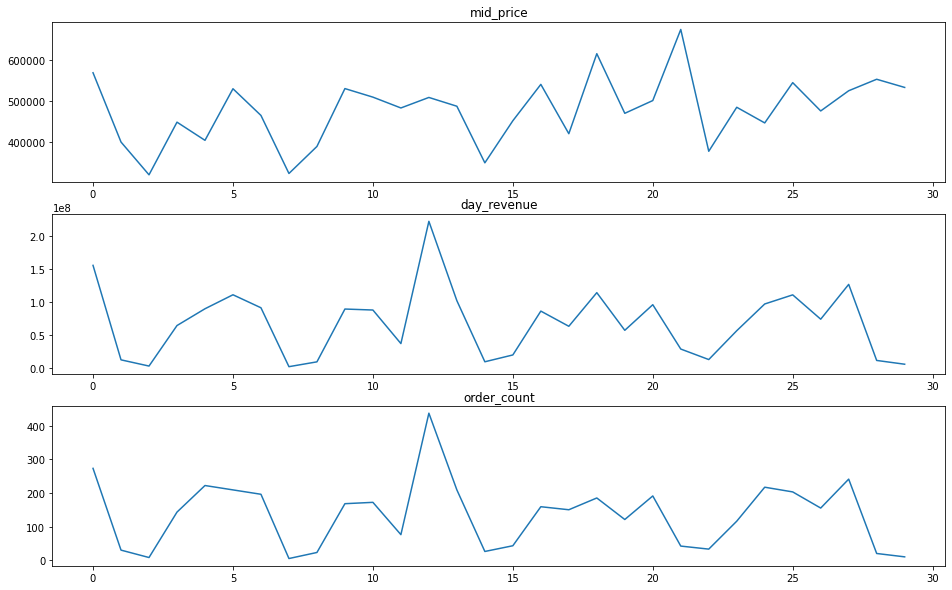

In [23]:
currency = pd.read_csv('data/usd_rate.txt', sep=',', names=['date', 'currency_rate', 'type'])
currency = currency.drop('type', axis=1)
# usd = (currency.currency_rate.sum() / currency.date.count()).round(2)

# Объединение заказов, товаров и курса
df_full = pd.merge(orders_status, df_products, left_on='product_id', right_on='id', how='left')
df_full = df_full.drop('id', axis=1)
df_full = pd.merge(df_full, currency, on='date', how='left')

# Выручка
df_full['revenue'] = (df_full.price * df_full.currency_rate * df_full.quantity)

# Выручка подтвержденных заказов
total_revenue = df_full.query("status == 'confirmed'").revenue.sum().round(2)

# Таблица только с подтвержденными заказами
df_confirmed = df_full.query("status == 'confirmed'")

# Средний чек
middle_price = (total_revenue / df_confirmed.order_id.nunique()).round(2)

# Динамика по дням
df_confirmed_per_day = df_confirmed\
                        .groupby('date', as_index=False)\
                        .agg({'revenue': 'sum', 'order_id': 'count'})\
                        .rename(columns={'revenue': 'day_revenue', 'order_id': 'order_count'})

df_confirmed_per_day['mid_price'] = df_confirmed_per_day.day_revenue / df_confirmed_per_day.order_count

# Графики
plt.subplot(3, 1, 1)
df_confirmed_per_day.mid_price.plot(figsize=(16, 10))
plt.title('mid_price')
plt.subplot(3, 1, 2)
df_confirmed_per_day.day_revenue.plot(figsize=(16, 10))
plt.title('day_revenue')
plt.subplot(3, 1, 3)
df_confirmed_per_day.order_count.plot(figsize=(16, 10))
plt.title('order_count')

# Бренды
df_full['brand'] = df_full.name.str.split(',').str[0]

df_full.groupby(['brand', 'status'])\
        .agg({'revenue': 'sum', 'status': 'count'})\
        .rename(columns={'status': 'count'})\
        .sort_values('revenue')

# Никогда не заказанные товары
product_id_unique = df_confirmed.product_id.unique().tolist()
df_products['is_in_orders'] = df_products.id.isin(product_id_unique)
df_products.groupby('is_in_orders').agg({'id': 'count'})

# Доля никогда не заказанных товаров по брендам
df_products['brand'] = df_products.name.str.split(',').str[0]
df_brands = df_products\
            .groupby('brand', as_index=False)\
            .agg({'id': 'count'})\
            .rename(columns={'id': 'count'})\
            .query("count >= 15")

df_brand_counts = df_full\
                .groupby('brand', as_index=False)\
                .agg({'product_id': 'nunique'})

df_brands = pd.merge(df_brands, df_brand_counts, on='brand', how='left')

df_brands.query('product_id <= count/2')

# Отчёт по менеджерам
total_orders = df_confirmed.order_id.nunique()
total_revenue = df_confirmed.revenue.sum()

df_confirmed_per_manager = df_confirmed\
                            .groupby('manager', as_index=False)\
                            .agg({'revenue': 'sum', 'order_id': 'nunique'}).sort_values('revenue', ascending=False)
df_confirmed_per_manager.revenue = (df_confirmed_per_manager.revenue * 100 / total_revenue).round(2)
df_confirmed_per_manager.order_id = (df_confirmed_per_manager.order_id * 100 / total_orders).round(2)

**Ключевые инсайты:**
- **Выручка за месяц** — 2 038 231 821.56 руб., **средний чек** — 6 596 219.49 руб. 
- **Лидер по выручке** — бренд **JBL** (266.6 млн руб.), он же лидер по числу заказов (592)
- **Треть товаров (497 из 1677)** не была заказана ни разу. У брендов **Dali, KEF, Marantz, Pioneer** доля не заказанных товаров превышает половину — они занимают «полку» впустую
- **Лучший менеджер по выручке** — Маргарита Камертонова (17.04%), по числу заказов — Виктор Тромбонов (16.18%). Явной пятёрки лидеров с большим отрывом нет

<details>
<summary>&#9658; Click here to see the English version of the description</summary>
  <p>
      
**Key insights:**

 - **Monthly revenue** is 2,038,231,821.56 rubles, average order value is 6,596,219.49 rubles.
 - **The revenue leader** is the JBL brand (266.6 million rubles), and it is also the leader in the number of orders (592).
 - **A third of the products (497 out of 1,677)** were never ordered. For the Dali, KEF, Marantz, and Pioneer brands, the share of never-ordered products exceeds half — they are taking up shelf space for nothing.
 - **The best manager by revenue** is Margarita Kamertonova (17.04%), by number of orders — Viktor Trombonov (16.18%). There is no clear top five leaders with a large gap.
     
</p>
</details>